# 🎵 MoodBeats Lab 2: Can the Computer Find the Moods on Its Own?
### A Catholic Introduction to Artificial Intelligence — Unsupervised Learning with k-Means

In the first MoodBeats lab, **you gave the computer the answer key.** Every song came with a `mood` label (Happy, Sad, Relaxed, Motivated), and the model learned to copy those labels. That is **supervised learning**: a teacher supervises by supplying the right answers.

Today we take the answer key away.

**k-means clustering** is a kind of **unsupervised learning**. It gets the songs' sound measurements and nothing else. Its only job is to sort the songs into *k* groups so that songs in the same group are as close together as possible. It doesn't know what a "mood" is. It doesn't even know it's looking at music.

**The big question:** If the computer sorts the songs by sound alone, will its groups match the moods humans assigned?

### How k-means works (in four steps)
1. Drop *k* random "center points" into the data.
2. Assign every song to its nearest center.
3. Move each center to the average position of the songs assigned to it.
4. Repeat steps 2–3 until the centers stop moving.

That's the whole algorithm. Everything it "knows" comes from one idea: **distance**.

### What you'll do
| Step | What happens |
|---|---|
| 1 | Load and clean the data |
| 2 | Hide the answer key |
| 3 | Experiment 1: cluster *without* scaling (and watch it go wrong) |
| 4 | Experiment 2: cluster *with* scaling |
| 5 | Meet your clusters, and **name them yourself** |
| 6 | How many groups are there, really? |
| 7 | The Reveal: compare clusters to moods |
| 8 | Where did "Motivated" go? |
| 9 | Picture it in 2D |
| 10 | Reflection |

> 💡 Put `spotify_tracks_mood.csv` in the same folder as this notebook before you start. Everything here runs on a regular laptop with no GPU.

## INSTRUCTIONS:

- Be sure all cells run without error.

- Where you see this ---> ✍️ Your Observations, write down your observations. Be sure to follow the rules from the Student Writing Guidelines and use numbers from the notebook to support your answer.

## Step 0: Setup

In [1]:
# Install the necessary libraries if you haven't already
%pip install pandas numpy scikit-learn matplotlib seaborn

# Install the necessary libraries if you haven't already


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.precision", 2)
SEED = 42   # keeps everyone's results the same
print("Ready!")

Ready!


## Step 1: Load and Clean the Data

In [3]:
df = pd.read_csv("spotify_tracks_mood.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (114000, 17)


,id,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,mood
0,5SuOikwiRyPMVoIQDJUgSV,73,230666,0,0.68,0.46,1,-6.75,0,0.14,0.03,1.01e-06,0.36,0.71,87.92,4,Happy
1,4qPNDBW1i3p13qLCt0Ki3A,55,149610,0,0.42,0.17,1,-17.23,1,0.08,0.92,5.56e-06,0.10,0.27,77.49,4,Sad
2,1iJBSr7s7jYXzM8EGcbK5b,57,210826,0,0.44,0.36,0,-9.73,1,0.06,0.21,0.00e+00,0.12,0.12,76.33,4,Sad
3,6lfxq3CG4xtTiEg7opyCyx,71,201933,0,0.27,0.06,0,-18.52,1,0.04,0.91,7.07e-05,0.13,0.14,181.74,3,Sad
4,5vjLSffimiIP26QG5WcN2K,82,198853,0,0.62,0.44,2,-9.68,1,0.05,0.47,0.00e+00,0.08,0.17,119.95,4,Happy


Some songs appear more than once (the same track listed on several albums or playlists). Each has the same `id`, so we keep one copy of each. We also drop songs with a `tempo` of 0, which means the measurement failed (often silence or a spoken track).

In [19]:
before = len(df)
df = df.drop_duplicates(subset="id")
after_dupes = len(df)
df = df[df["tempo"] > 0].reset_index(drop=True)

print(f"Started with:            {before:,} rows")
print(f"Removed duplicates:      {before - after_dupes:,}")
print(f"Removed tempo = 0:       {after_dupes - len(df):,}")
print(f"Songs left to cluster:   {len(df):,}")

Started with:            89,584 rows
Removed duplicates:      0
Removed tempo = 0:       0
Songs left to cluster:   89,584


In [5]:
print("How the human-assigned moods are spread out:")
print(df["mood"].value_counts())

How the human-assigned moods are spread out:
mood
Happy        50789
Sad          19459
Relaxed      11394
Motivated     7942
Name: count, dtype: int64


## Step 2: Hide the Answer Key 🙈

We give k-means only measurements of **how each song sounds**. We leave out:

- **`mood`**: the answer key. That's the whole point.
- **`explicit`, `mode`**: on/off (0/1) columns. k-means measures straight-line distance, and a jump from 0 to 1 doesn't mean "a little more" of anything.
- **`key`, `time_signature`**: these are numbers, but they're really *categories*. Key 11 (B) isn't "more" than key 1 (C♯).
- **`popularity`, `duration_ms`**: facts *about* the song, not its sound.

In [20]:
SOUND_FEATURES = ["danceability", "energy", "loudness", "speechiness",
                  "acousticness", "instrumentalness", "liveness",
                  "valence", "tempo"]

X = df[SOUND_FEATURES]          # what k-means gets to see
answer_key = df["mood"]         # locked away until Step 7

X.describe().loc[["min", "max", "mean"]]

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
min,0.05,2.02e-05,-46.59,0.02,0.00,0.00,9.25e-03,0.00,30.20
max,0.98,1.00e+00,4.53,0.96,1.00,1.00,1.00e+00,0.99,243.37
mean,0.56,6.35e-01,-8.48,0.09,0.33,0.17,2.17e-01,0.47,122.27


### Observation(s):

- Tempo (0 to about 243) and loudness (about −50 to 4.5) have much bigger numbers than the other columns, which all run from 0 to 1.

- This matters because the algorithm decides whether two songs are “close” by adding up the differences in each column. A difference of 20 in tempo is small musically, but it’s huge compared to the biggest possible difference in danceability or energy, which is only 1. So tempo and loudness would end up deciding which songs count as similar, and the other columns would barely count at all. Two songs could have totally different moods and energy and still be called “close” just because their tempos match.

- To be fair to every column, we should put them all on the same scale before measuring distance, for example by shrinking every column to run from 0 to 1. This is what `scaling` does.

## Step 3: Experiment 1 — Cluster *Without* Scaling

Let's ask for 4 groups (one for each mood) and see what happens if we just hand k-means the raw numbers.

In [7]:
km_raw = KMeans(n_clusters=4, n_init=10, random_state=SEED)
raw_labels = km_raw.fit_predict(X)

# The average song in each cluster
pd.DataFrame(km_raw.cluster_centers_, columns=SOUND_FEATURES).round(2)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.62,0.65,-8.40,0.07,0.30,0.19,0.21,0.48,117.54
1,0.49,0.72,-7.03,0.11,0.25,0.15,0.22,0.50,173.48
2,0.54,0.55,-9.80,0.10,0.44,0.18,0.22,0.44,87.55
3,0.56,0.67,-7.83,0.08,0.29,0.16,0.22,0.47,140.70


### ✍️ Your Observations
*Compare the four rows. Clusters are numbered 0-3. Which column changes a lot from cluster to cluster? Which columns barely change at all? What do you think k-means actually sorted the songs by?*

<details>
<summary>💡 Hint</summary>

- The column showing the greater variability across its range is usually how k-means sorts.

</details>

> _The column that changes significantly more than the others is tempo - ranging from 87.55 to 173.48.  The other columns differ no more than the significand, all having the same order of magnitude.  This means that k-means sorted the songs by their tempo.  The other values in the other columns are all around the average values of each quality for the entire data set._

## Step 4: Experiment 2 — Cluster *With* Scaling

**Scaling** puts every column on the same footing. `StandardScaler` converts each value into "how many steps above or below average is this song?" (statisticians call these steps *standard deviations*). After scaling, a big jump in tempo and a big jump in energy count the same.

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=SOUND_FEATURES).describe().loc[["min", "max", "mean"]]

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
min,-2.92e+00,-2.48e+00,-7.36e+00,-5.78e-01,-9.70e-01,-5.34e-01,-1.07e+00,-1.79e+00,-3.10e+00
max,2.41e+00,1.43e+00,2.51e+00,7.74e+00,1.98e+00,2.56e+00,4.03e+00,2.00e+00,4.08e+00
mean,-7.20e-17,-2.03e-16,-8.63e-17,-8.12e-17,-4.06e-17,-9.64e-17,1.05e-16,2.54e-17,-2.44e-16


In [21]:
km = KMeans(n_clusters=4, n_init=10, random_state=SEED)
raw_numbers = km.fit_predict(X_scaled)

# k-means numbers its clusters 0-3 in no particular order.
# We rename them A, B, C, D from largest to smallest so everyone's labels match.
order = pd.Series(raw_numbers).value_counts().index
rename = {old: letter for old, letter in zip(order, "ABCD")}
df["cluster"] = pd.Series(raw_numbers).map(rename)

print("Songs in each cluster:")
print(df["cluster"].value_counts().sort_index())

Songs in each cluster:
cluster
A    36611
B    27318
C    18653
D     7002
Name: count, dtype: int64


## Step 5: Meet Your Clusters 👋

Here is the average song in each cluster, back in the original units so you can read them.

In [10]:
profile = df.groupby("cluster")[SOUND_FEATURES].mean()
profile

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster,,,,,,,,,
A,0.69,0.68,-7.03,0.09,0.28,0.06,0.16,0.67,118.43
B,0.48,0.80,-6.03,0.08,0.08,0.23,0.19,0.33,136.53
C,0.45,0.27,-15.13,0.05,0.78,0.35,0.16,0.28,109.83
D,0.53,0.74,-7.85,0.21,0.37,0.07,0.74,0.49,119.89


Raw averages are hard to compare (is a loudness of −15 a lot?). The chart below shows each cluster in **scaled units**: blue means below the average song, red means above, and the number says by how many steps.

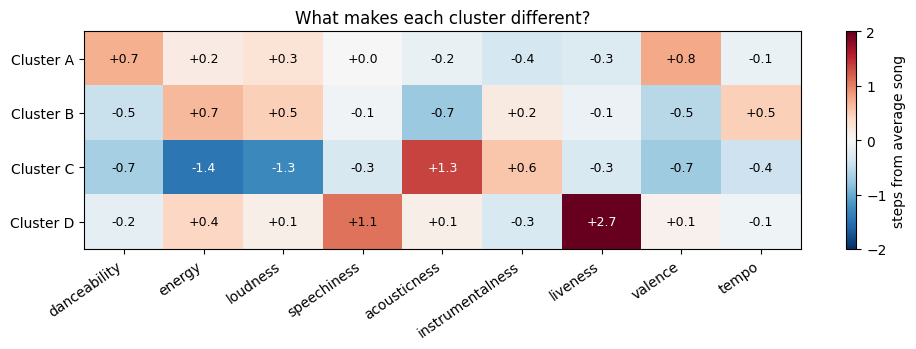

In [11]:
z_profile = pd.DataFrame(X_scaled, columns=SOUND_FEATURES).groupby(df["cluster"]).mean()

fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(z_profile.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(SOUND_FEATURES)), SOUND_FEATURES, rotation=35, ha="right")
ax.set_yticks(range(len(z_profile)), [f"Cluster {c}" for c in z_profile.index])
for i in range(z_profile.shape[0]):
    for j in range(z_profile.shape[1]):
        v = z_profile.values[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center",
                color="white" if abs(v) > 1.2 else "black", fontsize=9)
fig.colorbar(im, ax=ax, label="steps from average song")
ax.set_title("What makes each cluster different?")
plt.tight_layout()
plt.show()

### ✍️ Your turn: Name the clusters (before you peek!)

k-means gave us letters, not names. **Naming is a human job.** Using the chart above, write a short name for each cluster in the cell below, like "Quiet Acoustic Songs" or "Loud Dance Tracks." Don't use the four mood words yet.  Which categories are above average?  Below average? Answer: `Songs in this cluster are..."`

In [22]:
my_names = {
    "A": "high-valence dance",
    "B": "loud-energetic electric",
    "C": "Acoustic-Instrumental",
    "D": "lively recitation",
}
my_names

{'A': 'high-valence dance',
 'B': 'loud-energetic electric',
 'C': 'Acoustic-Instrumental',
 'D': 'lively recitation'}

### ✍️ Your Observations
*Which cluster was easiest to name? Which was hardest? Did any cluster surprise you?*

> _The cluster that was the easiest to name was A.  The hardest to name was B.  The cluster that surprizes me the most was Cluster D, which had a liveliness value of +2.7._

## Step 6: How Many Groups Are There, Really?

We asked for 4 clusters because there are 4 moods. But the music didn't tell us that; *we* did. Let's ask k-means for 2 through 8 clusters and score each try two ways:

- **Inertia** (left chart): the total distance from each song to its cluster's center. Lower is tighter. It *always* drops as you add clusters, so we look for an **"elbow"** where adding more stops helping much.
- **Silhouette score** (right chart): roughly, "Is each song much closer to its own cluster than to the next-nearest one?" It runs from −1 to 1, and higher means cleaner, more separate groups. (We score a random sample of 5,000 songs to keep it fast.)

k = 2:  inertia =   632,605   silhouette = 0.259
k = 3:  inertia =   561,067   silhouette = 0.167
k = 4:  inertia =   504,721   silhouette = 0.172
k = 5:  inertia =   455,861   silhouette = 0.184
k = 6:  inertia =   414,775   silhouette = 0.194
k = 7:  inertia =   376,645   silhouette = 0.200
k = 8:  inertia =   355,573   silhouette = 0.180


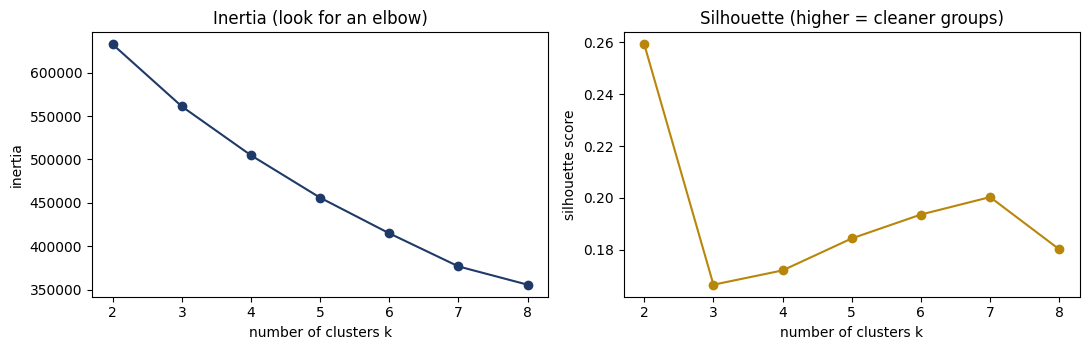

In [23]:
ks = range(2, 9)
inertias, silhouettes = [], []
sample = np.random.RandomState(SEED).choice(len(X_scaled), 5000, replace=False)

for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled[sample], model.labels_[sample]))
    print(f"k = {k}:  inertia = {model.inertia_:>9,.0f}   silhouette = {silhouettes[-1]:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(list(ks), inertias, "o-", color="#1f3a68")
ax1.set(title="Inertia (look for an elbow)", xlabel="number of clusters k", ylabel="inertia")
ax2.plot(list(ks), silhouettes, "o-", color="#b8860b")
ax2.set(title="Silhouette (higher = cleaner groups)", xlabel="number of clusters k", ylabel="silhouette score")
plt.tight_layout()
plt.show()

### ✍️ Your Observations

Left Chart: What's important here are the number of clusters (k): how many clusters before the curve flattens out (called the **elbow**). Right Chart:  Higher is better, so you want the highest point, not a bend.

*Is there a clear elbow in the left chart? Describe what you see. In the right chart, which k(s) gets the best silhouette score? Describe what you see.*

> _There is no clear elbow in the left chart, but rather there appears to be a curve with downward direction and upward concavity.  In the right chart, the best silhouette score is from k=2.  This indicates that a cluster division of 2 likely divides all of the music by one heighly weighted variable or multiple correlated values, resulting in groups like "high energy" and "low energy".  I see that after that the values increase from k=3 to k=7.  At k=7, there may be 7 distinct subgroups, possibly indicating something useful from the music._

## Step 7: The Reveal 🎭

Time to unlock the answer key. This table counts how many songs of each mood landed in each cluster.

In [24]:
reveal = pd.crosstab(df["cluster"], answer_key)
reveal

mood,Happy,Motivated,Relaxed,Sad
cluster,,,,
A,29297,4032,1997,1285
B,16752,2353,7894,319
C,190,242,965,17256
D,4550,1315,538,599


Raw counts are hard to compare because Happy songs outnumber everything else. Here is the same table as **percentages of each cluster**.

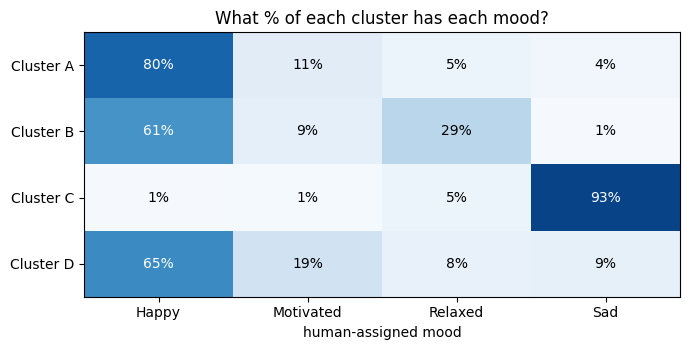

Biggest mood in each cluster:
  Cluster A: 80% Happy
  Cluster B: 61% Happy
  Cluster C: 93% Sad
  Cluster D: 65% Happy


In [15]:
reveal_pct = pd.crosstab(df["cluster"], answer_key, normalize="index") * 100

fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(reveal_pct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(reveal_pct.shape[1]), reveal_pct.columns)
ax.set_yticks(range(reveal_pct.shape[0]), [f"Cluster {c}" for c in reveal_pct.index])
for i in range(reveal_pct.shape[0]):
    for j in range(reveal_pct.shape[1]):
        v = reveal_pct.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center",
                color="white" if v > 60 else "black")
ax.set_title("What % of each cluster has each mood?")
ax.set_xlabel("human-assigned mood")
plt.tight_layout()
plt.show()

print("Biggest mood in each cluster:")
for c in reveal_pct.index:
    top = reveal_pct.loc[c].idxmax()
    print(f"  Cluster {c}: {reveal_pct.loc[c, top]:.0f}% {top}")

### ✍️ Your Observations
*Which cluster matches a single mood best? Which moods never get a cluster of their own? Compare these results to the names you chose in Step 5.*

> _Cluster C matches Sad the best at 93% sad.  Relaxed and Motivated never get a cluster of their own.  These results are correlating well enough to the names that I chose in step 5, still without enough information however to tell if I really named the categories correctly, since I only know what other people have said about the songs and cannot know specifically whether they fit together and how._

## Step 8: Where Did "Motivated" Go? 🕵️

In the first MoodBeats lab we noticed something odd about the `explicit` column. Let's look again: what share of explicit and non-explicit songs got each mood?

In [16]:
pd.crosstab(df["explicit"].map({0: "not explicit", 1: "explicit"}),
            answer_key, normalize="index").mul(100).round(1)

mood,Happy,Motivated,Relaxed,Sad
explicit,,,,
explicit,0.0,98.9,0.7,0.4
not explicit,62.0,0.4,13.8,23.7


### Experiment 3: Let k-means see the `explicit` column
We left `explicit` out in Step 2 because it isn't a sound measurement. What happens if we add it back?

In [17]:
X_plus = StandardScaler().fit_transform(df[SOUND_FEATURES + ["explicit"]])
plus_labels = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(X_plus)

order = pd.Series(plus_labels).value_counts().index
plus_clusters = pd.Series(plus_labels).map({old: l for old, l in zip(order, "ABCD")})
pd.crosstab(plus_clusters.rename("cluster"), answer_key)

mood,Happy,Motivated,Relaxed,Sad
cluster,,,,
A,31745,8,2182,1390
B,18819,8,8112,374
C,213,0,1045,17674
D,12,7926,55,21


### ✍️ Your Observations
*What happened once k-means could see `explicit`? What does this tell you about how the "Motivated" label was probably made (by a data annotator or a rule, like "if explicit, call it Motivated")? Is "Motivated" really a sound?*

> _Once the model could see 'explicit' it grouped the motivated songs together into category D.  This shows that explicit and motivated are highly interconnected, since they seem to have similar corresponding values that cause enough shift in weight for the model to categorize the motivated songs together.  This either shows that the data labeler made the call "if explicit, call it Motivated", or the data simply reflects a music industry where producers make most Motivated songs use explicit words, phrases, and concepts.  Motivated, like all of the other Moods, is not a sound but a reaction to the song._

## Step 9: Picture It in 2D

We can't draw 9 dimensions. **PCA** (Principal Component Analysis) squashes all 9 features down to the 2 directions where the songs spread out the most, so we can make a flat map. Some detail is lost, but nearby dots are still similar songs. We plot a random sample of 3,000 songs.

These 2 directions keep 48% of the spread in the data.


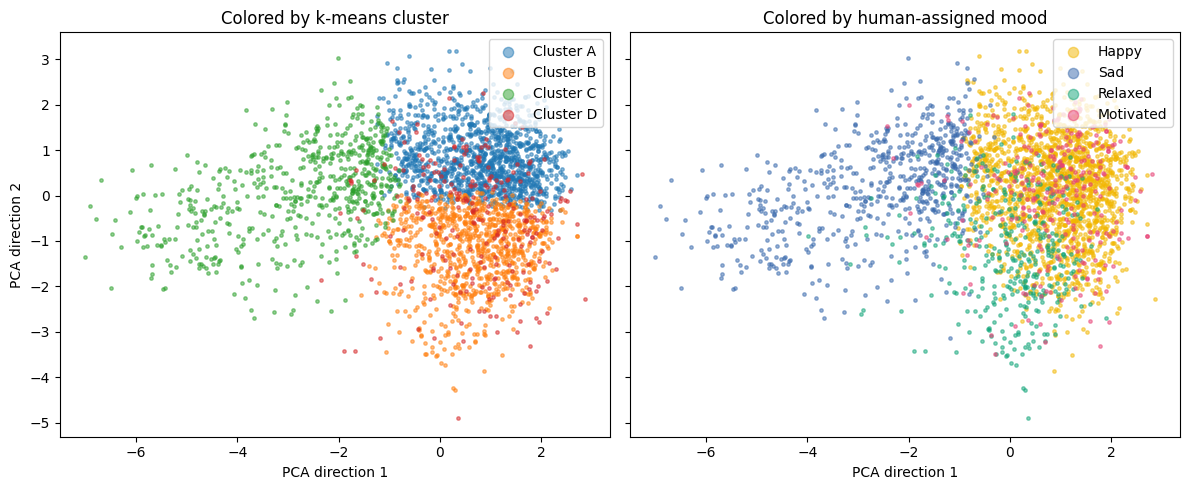

In [25]:
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X_scaled)
print(f"These 2 directions keep {pca.explained_variance_ratio_.sum():.0%} of the spread in the data.")

pick = np.random.RandomState(SEED).choice(len(coords), 3000, replace=False)
cluster_colors = {"A": "#1f77b4", "B": "#ff7f0e", "C": "#2ca02c", "D": "#d62728"}
mood_colors = {"Happy": "#f2b701", "Sad": "#3969ac", "Relaxed": "#11a579", "Motivated": "#e73f74"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for c, col in cluster_colors.items():
    m = (df["cluster"].values[pick] == c)
    ax1.scatter(coords[pick][m, 0], coords[pick][m, 1], s=6, alpha=0.5, color=col, label=f"Cluster {c}")
for mood, col in mood_colors.items():
    m = (answer_key.values[pick] == mood)
    ax2.scatter(coords[pick][m, 0], coords[pick][m, 1], s=6, alpha=0.5, color=col, label=mood)
ax1.set(title="Colored by k-means cluster", xlabel="PCA direction 1", ylabel="PCA direction 2")
ax2.set(title="Colored by human-assigned mood", xlabel="PCA direction 1")
for ax in (ax1, ax2):
    ax.legend(markerscale=3, loc="upper right")
plt.tight_layout()
plt.show()

### ✍️ Your Observations
*Compare the two maps. Where do they agree? Where do the moods overlap so much that no straight-line boundary could separate them?*

> _The two maps seem to agree in the cases of Cluster C=Sad. Clusters A, B, and C together overlap with Happy, Relaxed, and Motivated, but not enough for any one pair of cluster and group to be considered similar.

>_In the right chart, the moods happy, motivated, and relaxed overlap so much that they seem homogenious.  This agrees with reality, since happiness is not opposed to relaxation or motivation.  Each song should be considered having a happiness-sadness value, and a motivation-relaxation value.  A song can after all be both 100% happy and 100% motivated._


## ✍️ Step 9: Reflection

Answer **one** of the following questions in this part in 3-5 sentences each. Use specific numbers from your notebook!

1. **Who names the groups?** k-means produced letters, not names. You named the clusters in Step 5. When companies cluster *people* (shoppers, voters, students, patients), someone names those groups too: "high-risk," "low-value," "likely to quit." How does the Church's teaching that each person is made in the image of God (*Imago Dei*) challenge the idea that a person *is* the group an algorithm put them in?

> _When people are put into groups and assigned values, they are at a significant risk of becoming de-humanized in the eyes of others.  If being in a different group correlates to moral or immoral treatment, than that grouping is likewise moral or immoral.  Grouping people into categories is not wrong on its own any more than grouping people into brunettes, blondes, and redheads is.  What is wrong however is when certain groups are treated injustly, or their dignity is forgotten._

2. **Are the categories real?** The data never "asked" for 4 groups, and "Motivated" turned out to be mostly a lyrics flag rather than a sound. What does this suggest about labels and categories that people build into a dataset? Who should be responsible for checking them?

> _Double-click this cell and type your answer here. Be sure to follow the course's Student Writing Guidelines and use numbers from the notebook to support your answer._

3. **The technocratic paradigm.** Pope Francis and Pope Leo XIV warn against treating reality as only what can be measured and calculated. A song's mood is something people *experience*. What can sound measurements capture about music, and what do they miss?

> _Double-click this cell and type your answer here. Be sure to follow the course's Student Writing Guidelines and use numbers from the notebook to support your answer._


© 2026 D. E. Goddu. All rights reserved.
Developed by the author with the assistance of AI tools (Claude, Anthropic). All content was selected, reviewed, and edited by the author.